# East Boston Sea Level Rise: Data Ingestion + Baseline Parcel Model

**Goal:** build one row per parcel in East Boston with flood exposure, ground elevation, impervious cover, social vulnerability, and critical assets, then compute a transparent baseline score (risk, confidence, feasibility flags). This is the EDA layer that the LLM solutioning step will sit on later.

**Pipeline**

1. Study area (East Boston boundary)
2. Ingest six sources: parcels, Climate Ready Boston flood extents (21" and 36"), 1 m DEM, impervious cover, social vulnerability, critical assets + shoreline
3. QA maps
4. Parcel feature table
5. Baseline scoring
6. Exports for the next stage

**Conventions**

- Working CRS: **EPSG:26986** (Massachusetts State Plane, meters), same as the Fort Point work.
- Everything downloaded is cached in `data/raw/`, everything derived goes to `data/processed/`. Rerunning the notebook skips downloads that already exist.
- Every loader has a `MANUAL_PATHS` override. If an automatic download fails (URLs on city portals move), download the file by hand, point the path at it, and rerun that cell.

**Run order:** top to bottom. Cells marked *config* are the only ones you should need to edit.

## 0. Setup

In [ ]:
# Installs anything missing (a fresh Colab runtime has none of the geo stack).
# If it installs something, Runtime > Restart session, then run from the top.
import importlib.util, subprocess, sys
NEED = {"geopandas": "geopandas", "rasterio": "rasterio", "rasterstats": "rasterstats",
        "rioxarray": "rioxarray", "py3dep": "py3dep", "pygeohydro": "pygeohydro",
        "osmnx": "osmnx", "folium": "folium", "mapclassify": "mapclassify",
        "contextily": "contextily", "pyarrow": "pyarrow"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Done. Restart the session now, then run from the top.")
else:
    print("all packages present")


all packages present


In [ ]:
import os, re, json, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import requests
import rasterio
from rasterio import features as rio_features
from rasterio.mask import mask as rio_mask
from rasterstats import zonal_stats
from shapely.geometry import box, mapping
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")   # no force_remount: it drops the shortcut and is slow


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
parts = ["MDE", "SCI 6514: Geospatial", "Final-project", "EDA"]
p = Path("/content/drive/MyDrive")
print("MyDrive exists:", p.exists())
print("top level:", sorted(x.name for x in p.iterdir())[:40])
for part in parts:
    if not (p / part).exists():
        print(f"\n'{part}' not found in {p}")
        print("what is actually there:", sorted(x.name for x in p.iterdir())[:40])
        break
    p = p / part
    print("ok:", p)

MyDrive exists: True
top level: ['BIOPOD Co. - Real Talk Event.pdf', 'CLP', 'CNN_ManiniBanerjee_Sample.pdf', 'Colab Notebooks', 'KIRKLAND IMAGERY-compressed.pdf', 'LAB 1 - M&S Computing.gmap', 'MDE', 'MISC', "Manini Banerjee's_CV_2026_HackNation.pdf", "Manini Banerjee's_CV_FALL2026.pdf", "Manini Banerjee's_HARDMODE_CV_2026.pdf", 'Portfolio', 'Real Talk - VC Event!.pptx', 'hARVARD sHEET.gsheet']
ok: /content/drive/MyDrive/MDE
ok: /content/drive/MyDrive/MDE/SCI 6514: Geospatial
ok: /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project
ok: /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA


### Config *(edit here)*

In [ ]:
CRS = "EPSG:26986"            # MA State Plane meters
NEIGHBORHOOD = "East Boston"

# Study area. Default = the East Boston neighborhood polygon.
# To use a custom box instead (e.g. the Seaport / South Boston / Fort Point extent of your
# "Where the water comes in" map), set STUDY_BBOX_26986 = (minx, miny, maxx, maxy) in EPSG:26986
# metres and change NEIGHBORHOOD to a label for it. Leave as None for East Boston.
STUDY_BBOX_26986 = None

NODATA = -9999.0                # nodata value used in every raster this notebook writes

EDA_DIR = Path("/content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA")
if not EDA_DIR.exists():
    raise FileNotFoundError(
        f"{EDA_DIR} not found. The Drive shortcut is not visible in this runtime. In Drive, add the "
        "shared folder to 'My Drive' (right-click > Organize > Add shortcut), then rerun the mount cell. "
        "Without this check, mkdir would silently create an empty duplicate folder tree.")
DATA = EDA_DIR / "data"
RAW, PROC, FIG = DATA / "raw", DATA / "processed", DATA / "figures"
for d in (RAW, PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)
print("data folder:", DATA)

# Fallback study-area box (lon/lat) if the neighborhood boundary download fails.
EAST_BOSTON_BBOX = (-71.048, 42.352, -70.985, 42.400)

# Scenarios used in the baseline (Climate Ready Boston, average monthly high tide)
SCENARIOS = ["21", "36"]      # inches of sea level rise (2050s, 2070s)

# Logan Airport sits inside East Boston. Large Massport parcels (the airfield) swamp
# every statistic, so they are excluded by default. Smaller Massport waterfront
# parcels stay in and are tagged as public.
EXCLUDE_AIRFIELD = True
AIRFIELD_MIN_AREA_M2 = 100_000

# Manual overrides: set any of these to a local file path to skip the automatic download.
MANUAL_PATHS = {
    "boundary": None,          # polygon file containing East Boston
    "parcels": None,           # parcels joined with assessing data
    "flood_21": None,          # CRB 21" high tide extent
    "flood_36": None,          # CRB 36" high tide extent
    "dem": None,               # GeoTIFF, meters NAVD88 (e.g. your 1 m USGS 3DEP tile)
    "impervious": None,        # raster (0/1 or 0-100) OR MassGIS 2016 LCLU polygons (COVERNAME field)
    "social_vuln": None,       # CRB social vulnerability tracts
}

# Optional: known water surface elevations (m, NAVD88) per scenario. If None, the
# notebook estimates one from the DEM inside the flood extent (see Section 4).
WSE_OVERRIDE_M = {"21": None, "36": None}

# Scoring weights (Section 5). Keep simple and visible.
W_VULN = 0.5                  # risk = exposure_pct * ((1 - W_VULN) + W_VULN * vuln_pct)
CRITICAL_ASSET_BOOST = 1.25   # multiplier when a parcel holds a critical asset
EDGE_BAND_M = 0.30            # within this many meters of the water surface = low confidence
TOP_N = 20

data folder: /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA/data


### Helpers: caching, ArcGIS REST, Analyze Boston (CKAN)

ArcGIS REST = accessing the geospatial tools of ArcGIS
Analyze Boston CKAN >> City of Boston's official municipal open data portal, powered by CKAN (Comprehensive Knowledge Archive Network)

In [ ]:
CKAN = "https://data.boston.gov/api/3/action"
SESSION = requests.Session()
SESSION.headers.update({
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36",
    "Accept": "application/geo+json, application/json, application/zip, */*",
})
SOURCES = {}   # provenance log: layer -> where it came from

def cache_path(name, ext):
    return RAW / f"{name}.{ext}"

def to_crs(gdf):
    if gdf.crs is None:
        gdf = gdf.set_crs(4326)
    return gdf.to_crs(CRS)

def read_vector_cached(name, url):
    # Download through requests (browser headers), save locally, then read the file.
    p = cache_path(name, "parquet")
    if p.exists():
        return gpd.read_parquet(p)
    last = None
    for attempt in range(1, 4):
        r = SESSION.get(url, timeout=300, allow_redirects=True)
        r.raise_for_status()
        is_zip = url.lower().endswith(".zip") or r.content[:2] == b"PK"
        tmp = RAW / f"{name}{'.zip' if is_zip else '.geojson'}"
        tmp.write_bytes(r.content)
        want = r.headers.get("Content-Length")
        if want and want.isdigit() and int(want) != len(r.content) and "gzip" not in r.headers.get("Content-Encoding", ""):
            last = f"truncated download ({len(r.content)} of {want} bytes)"
        else:
            try:
                gdf = gpd.read_file(tmp)
                gdf.to_parquet(p)
                return gdf
            except Exception as e:                       # truncated or HTML error page saved as .geojson
                last = f"{type(e).__name__}: {e} | first bytes: {r.content[:120]!r}"
        print(f"  {name}: attempt {attempt} failed -> {last}")
        tmp.unlink(missing_ok=True)
    raise RuntimeError(f"Could not download a readable file for '{name}' from {url}\n{last}\n"
                       "Download it by hand and set MANUAL_PATHS.")

# ---- Analyze Boston (CKAN) ----
def ckan_search(query, rows=20):
    r = SESSION.get(f"{CKAN}/package_search", params={"q": query, "rows": rows}, timeout=60)
    r.raise_for_status()
    return r.json()["result"]["results"]

def ckan_geo_resource(pkg):
    # Pick the best machine-readable geo resource in a CKAN package.
    res = pkg.get("resources", [])
    def score(r):
        fmt = (r.get("format") or "").lower(); url = (r.get("url") or "").lower()
        if "geojson" in fmt or url.endswith(".geojson") or "geojson" in url: return 3
        if "shp" in fmt or "shapefile" in fmt or url.endswith(".zip"): return 2
        if "kml" in fmt: return 1
        return 0
    res = sorted(res, key=score, reverse=True)
    return res[0]["url"] if res and score(res[0]) > 0 else None

def ckan_find(query, title_regex, show=True):
    # Search Analyze Boston, return (title, url) of the first package whose title matches.
    pkgs = ckan_search(query)
    if show:
        print(f"Analyze Boston search '{query}':")
        for p in pkgs[:10]:
            print("   -", p["title"])
    for p in pkgs:
        if re.search(title_regex, p["title"], flags=re.I):
            url = ckan_geo_resource(p)
            if url:
                return p["title"], url
    print(f"No title matched /{title_regex}/. Titles returned by the search:")
    for p in pkgs:
        print("   -", p["title"])
    raise LookupError(f"No package matching /{title_regex}/ for query '{query}'. Set MANUAL_PATHS.")

# ---- ArcGIS REST (MapServer / FeatureServer) ----
def arcgis_polygon_layer(service_url):
    info = SESSION.get(service_url, params={"f": "json"}, timeout=60).json()
    for lyr in info.get("layers", []):
        if lyr.get("geometryType") == "esriGeometryPolygon" or "parcel" in lyr.get("name", "").lower():
            return f"{service_url}/{lyr['id']}"
    return f"{service_url}/0"

def arcgis_query(layer_url, bounds_4326, chunk=500):
    # Pull every feature intersecting a lon/lat box, in object-id batches (works without pagination support).
    minx, miny, maxx, maxy = bounds_4326
    base = dict(geometry=f"{minx},{miny},{maxx},{maxy}", geometryType="esriGeometryEnvelope",
                inSR=4326, spatialRel="esriSpatialRelIntersects", where="1=1")
    ids = SESSION.get(f"{layer_url}/query", params={**base, "returnIdsOnly": "true", "f": "json"},
                      timeout=120).json().get("objectIds") or []
    print(f"{len(ids)} features to fetch from {layer_url}")
    parts = []
    for i in range(0, len(ids), chunk):
        batch = ",".join(map(str, ids[i:i + chunk]))
        r = SESSION.post(f"{layer_url}/query", data={"objectIds": batch, "outFields": "*",
                         "outSR": 4326, "returnGeometry": "true", "f": "geojson"}, timeout=300)
        r.raise_for_status()
        feats = r.json().get("features", [])
        if feats:
            parts.append(gpd.GeoDataFrame.from_features(feats, crs=4326))
    if not parts:
        raise RuntimeError("Query returned no features.")
    return pd.concat(parts, ignore_index=True)

def pick_col(df, candidates):
    # Case-insensitive column lookup; returns the first match or None.
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]
    return None

## 1. Study area
GeoDataFrame = A GeoDataFrame object is a pandas.DataFrame that has one or more columns containing geometry. holds Shapely geometric objects (such as Point, LineString, or Polygon)

Analyze Boston search 'neighborhood boundaries':
   - Boston Neighborhood Boundaries
   - Boston Neighborhood Boundaries Approximated by 2020 Census Tracts
   - Boston Neighborhood Boundaries Approximated by 2020 Census Block Groups
   - Census Tracts Boston (2020)
   - Historical Boston Population Estimates 1950-2020 (Neighborhood Level)
   - Historical Boston Population Estimates 1950-2020 (Tract Level)
   - Historical Boston Population Estimates 1950-2020 (City Level)
   - Boston Neighborhood Boundaries approximated by 2020 Census Block Groups
   - Neighborhood Demographics
Analyze Boston: Boston Neighborhood Boundaries | area km2: 12.21


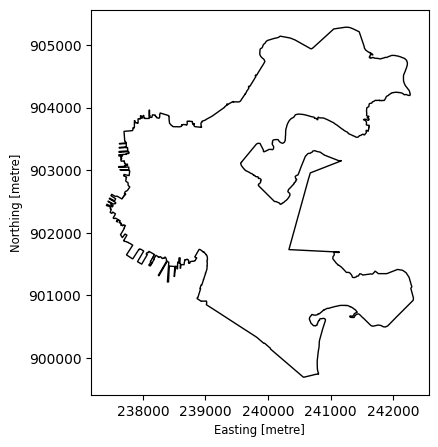

In [ ]:
def load_boundary():
    if STUDY_BBOX_26986:
        SOURCES["boundary"] = f"custom bbox {STUDY_BBOX_26986} (EPSG:26986)"
        return gpd.GeoDataFrame({"name": [NEIGHBORHOOD]}, geometry=[box(*STUDY_BBOX_26986)], crs=CRS)
    if MANUAL_PATHS["boundary"]:
        g = gpd.read_file(MANUAL_PATHS["boundary"]); SOURCES["boundary"] = MANUAL_PATHS["boundary"]
    else:
        try:
            title, url = ckan_find("neighborhood boundaries", r"neighborhood")
            g = read_vector_cached("neighborhoods", url); SOURCES["boundary"] = f"Analyze Boston: {title}"
        except Exception as e:
            print("Boundary download failed, using fallback bbox:", e)
            SOURCES["boundary"] = "fallback bbox"
            return gpd.GeoDataFrame({"name": [NEIGHBORHOOD]}, geometry=[box(*EAST_BOSTON_BBOX)], crs=4326).to_crs(CRS)
    g = to_crs(g)
    str_cols = g.select_dtypes(include=["object", "string"]).columns
    hit = g[g[str_cols].apply(lambda col: col.astype(str).str.fullmatch(NEIGHBORHOOD, case=False)).any(axis=1)]
    if hit.empty:
        raise LookupError(f"'{NEIGHBORHOOD}' not found in boundary columns {list(str_cols)}")
    return gpd.GeoDataFrame({"name": [NEIGHBORHOOD]}, geometry=[hit.union_all()], crs=CRS)

aoi = load_boundary()
aoi_4326 = aoi.to_crs(4326)
AOI_BOUNDS_4326 = tuple(aoi_4326.total_bounds)
print(SOURCES["boundary"], "| area km2:", round(aoi.area.iloc[0] / 1e6, 2))
aoi.plot(figsize=(5, 5), edgecolor="k", facecolor="none");

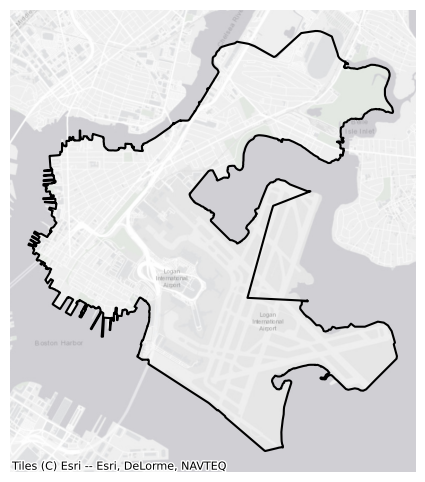

In [ ]:
import contextily as cx
ax = aoi.plot(figsize=(6, 6), edgecolor="k", facecolor="none", linewidth=1.5)
try:
    cx.add_basemap(ax, crs=aoi.crs, source=cx.providers.Esri.WorldGrayCanvas)   # CARTO now needs an API key
except Exception as e:
    print("Basemap tiles unavailable, continuing without:", e)
ax.set_axis_off()


## 2. Ingest

### 2.1 Parcels + assessing data
Source: City of Boston Assessing, FY25 property assessment joined to parcel polygons (`gis.boston.gov`). TEAM: If the city publishes a newer year, change `PARCEL_SERVICE`.

Two things this cell handles:
- **Condos.** The assessing join repeats the parcel polygon once per condo unit. Rows are collapsed to one per parcel, keeping total value and a unit count.
- **Owner type.** Owners are classified as `public`, `exempt` (tax-exempt, mostly institutions), or `private`. Public ownership is the main feasibility signal for the MVP. public ownership is a reasonable first filter for “could a planner act on this soon?” >> but this is just a simplification signal for now

In [ ]:
PARCEL_SERVICE = "https://gis.boston.gov/arcgis/rest/services/Assessing/Property_Assessment_FY26/MapServer"

PUBLIC_KEYWORDS = [
    "CITY OF BOSTON", "BOSTON CITY OF", "COMMONWEALTH OF MASS", "COMMONWEALTH MASS",
    "MASSACHUSETTS PORT", "MASS PORT", "MASSPORT", "BOSTON HOUSING AUTH",
    "BOSTON REDEVELOPMENT", "BOSTON PLANNING", "MASS BAY TRANS", "MBTA",
    "UNITED STATES", "U S A", "MASS DEPT", "DEPT OF CONSERVATION", "MASSDOT",
    "MASS HIGHWAY", "CONSERVATION COMM", "BOSTON PUBLIC",
]

def classify_owner(owner, lu):
    o = str(owner).upper()
    if any(k in o for k in PUBLIC_KEYWORDS):
        return "public"
    if str(lu).upper().strip() == "E":
        return "exempt"
    return "private"

def clean_parcels(raw):
    raw = to_crs(raw)
    c_id = pick_col(raw, ["GIS_ID", "MAP_PAR_ID", "PID_LONG", "PID"])
    c_own = pick_col(raw, ["OWNER", "OWNER_NAME"])
    c_lu = pick_col(raw, ["LU", "LAND_USE"])
    c_lud = pick_col(raw, ["LU_DESC", "LUC_DESC"])
    c_tv = pick_col(raw, ["TOTAL_VALUE", "AV_TOTAL", "TOTAL_VAL"])
    c_bv = pick_col(raw, ["BLDG_VALUE", "AV_BLDG"])
    c_yr = pick_col(raw, ["YR_BUILT", "YEAR_BUILT"])
    print("columns used:", dict(id=c_id, owner=c_own, lu=c_lu, lu_desc=c_lud, total=c_tv, bldg=c_bv, yr=c_yr))

    df = raw.copy()
    if c_id is None:                                 # fall back to identical geometry
        df["_pid"] = df.geometry.to_wkb().map(lambda b: hashlib.md5(b).hexdigest()); c_id = "_pid"
    for c in (c_tv, c_bv):
        if c: df[c] = pd.to_numeric(df[c].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
    if c_yr: df[c_yr] = pd.to_numeric(df[c_yr], errors="coerce")

    agg = {"geometry": "first"}
    if c_own: agg[c_own] = "first"
    if c_lu: agg[c_lu] = "first"
    if c_lud: agg[c_lud] = "first"
    if c_tv: agg[c_tv] = "sum"
    if c_bv: agg[c_bv] = "sum"
    if c_yr: agg[c_yr] = "min"
    g = df.groupby(c_id).agg(agg)
    g["n_units"] = df.groupby(c_id).size()
    g = gpd.GeoDataFrame(g.reset_index(), geometry="geometry", crs=CRS)
    g = g.rename(columns={c_id: "parcel_id", c_own: "owner", c_lu: "lu", c_lud: "lu_desc",
                          c_tv: "total_value", c_bv: "bldg_value", c_yr: "yr_built"})
    for col in ["owner", "lu", "lu_desc", "total_value", "bldg_value", "yr_built"]:
        if col not in g: g[col] = np.nan
    g["owner_type"] = [classify_owner(o, l) for o, l in zip(g["owner"], g["lu"])]
    g["geometry"] = g.geometry.make_valid()
    g["area_m2"] = g.area
    return g

def load_parcels():
    if MANUAL_PATHS["parcels"]:
        raw = gpd.read_file(MANUAL_PATHS["parcels"]); SOURCES["parcels"] = MANUAL_PATHS["parcels"]
    else:
        p = cache_path("parcels_raw", "parquet")
        if p.exists():
            raw = gpd.read_parquet(p)
        else:
            raw = arcgis_query(arcgis_polygon_layer(PARCEL_SERVICE), AOI_BOUNDS_4326)
            raw.to_parquet(p)
        SOURCES["parcels"] = PARCEL_SERVICE
    g = clean_parcels(raw)
    g = g[g.representative_point().within(aoi.geometry.iloc[0])].copy()   # inside East Boston only
    if EXCLUDE_AIRFIELD:
        airfield = (g["owner"].astype(str).str.upper().str.contains("MASSACHUSETTS PORT|MASSPORT|MASS PORT")
                    & (g["area_m2"] > AIRFIELD_MIN_AREA_M2))
        print(f"excluding {airfield.sum()} large Massport parcels (airfield)")
        g = g[~airfield].copy()
    return g.reset_index(drop=True)

In [ ]:
parcels = load_parcels()
print(len(parcels), "parcels")
display(parcels["owner_type"].value_counts())
parcels.head()

columns used: {'id': 'GIS_ID', 'owner': 'OWNER', 'lu': 'LU', 'lu_desc': 'LU_DESC', 'total': 'TOTAL_VALUE', 'bldg': 'BLDG_VALUE', 'yr': 'YR_BUILT'}
excluding 1 large Massport parcels (airfield)
6413 parcels


,count
owner_type,
private,6049
public,204
exempt,160


,parcel_id,geometry,owner,lu,lu_desc,total_value,bldg_value,yr_built,n_units,owner_type,area_m2
0,0100001000,"POLYGON ((238494.34 903305.899, 238500.215 903...",PASCUCCI CARLO,R3,THREE-FAM DWELLING,799000,610800,1900.0,1,private,114.629105
1,0100002000,"POLYGON ((238500.215 903308.976, 238505.486 90...",SEMBRANO RODERICK,R3,THREE-FAM DWELLING,843000,650500,1920.0,1,private,107.900431
2,0100003000,"POLYGON ((238505.486 903311.703, 238510.866 90...",GUERRA CHEVARRIA ANA S,R3,THREE-FAM DWELLING,815900,618400,1905.0,1,private,106.413221
3,0100004000,"POLYGON ((238510.866 903314.63, 238516.229 903...",JB REALTY TRUST,R3,THREE-FAM DWELLING,774100,570800,1900.0,1,private,110.796961
4,0100005000,"POLYGON ((238522.446 903305.058, 238528.002 90...",MARKS TRAVIS JOSEPH,R2,TWO-FAM DWELLING,771700,526900,1900.0,1,private,200.129841


### 2.2 Climate Ready Boston flood extents (21" and 36" sea level rise, high tide)
Source: Analyze Boston, Climate Ready Boston sea level rise layers (the city’s climate adaptation initiative, mapped which land would flood under three sea level rise scenarios). Flooded land at the average monthly high tide under each scenario. These are model outputs from the Boston Harbor Flood Risk Model reanalysis, so no hydro model is run here.

Note: the 36" layer is the same family you used for Fort Point ("Where the Water Comes In").

In [ ]:
def load_flood(scen):
    key = f"flood_{scen}"
    if MANUAL_PATHS[key]:
        g = gpd.read_file(MANUAL_PATHS[key]); SOURCES[key] = MANUAL_PATHS[key]
    else:
        title, url = ckan_find(f"{scen}inch sea level rise high tide", rf"^{scen}\s*-?\s*inch.*high tide", show=False)
        g = read_vector_cached(key, url); SOURCES[key] = f"Analyze Boston: {title}"
    g = to_crs(g)
    g["geometry"] = g.geometry.make_valid()
    clipped = g.clip(aoi.buffer(200))            # small buffer so edge parcels see the water
    if clipped.empty:
        raise RuntimeError(f"{key}: no flood polygons inside the study area. Check CRS / which dataset was picked.")
    return gpd.GeoDataFrame({"scenario": [scen]}, geometry=[clipped.union_all()], crs=CRS)

floods = {s: load_flood(s) for s in SCENARIOS}
for s, f in floods.items():
    print(f'{s}": {f.area.iloc[0] / 1e6:.2f} km2 flooded in/near AOI | {SOURCES[f"flood_{s}"]}')

21": 5.89 km2 flooded in/near AOI | Analyze Boston: 21inch Sea Level Rise High Tide
36": 6.93 km2 flooded in/near AOI | Analyze Boston: 36inch Sea Level Rise High Tide


### 2.3 Digital Elevation Model (1 m, meters NAVD88)
Source: USGS 3DEP via `py3dep` (same family as the 1 m DEM in your Fort Point comparison). Bare earth, so buildings and bridges are removed.

In [ ]:
DEM_RES_M = 1
TILE_M = 1500                  # request size per tile (metres); lower it if tiles still fail
DEM_PATH = PROC / f"dem_{DEM_RES_M}m_26986.tif"
DEM_TILES = RAW / f"dem_tiles_{DEM_RES_M}m"

def fetch_dem_tiles():
    # 3DEP's WMS fails on one big request. Fetch small tiles, retry, cache each tile on Drive.
    import time, py3dep, rioxarray
    from rioxarray.merge import merge_arrays
    DEM_TILES.mkdir(parents=True, exist_ok=True)
    study = aoi.buffer(300).geometry.iloc[0]
    minx, miny, maxx, maxy = study.bounds
    tiles = [box(x, y, min(x + TILE_M, maxx), min(y + TILE_M, maxy))
             for x in np.arange(minx, maxx, TILE_M) for y in np.arange(miny, maxy, TILE_M)]
    tiles = [t for t in tiles if t.intersects(study)]
    print(f"{len(tiles)} tiles of up to {TILE_M} m")
    parts = []
    for n, t in enumerate(tiles):
        f = DEM_TILES / f"tile_{n:03d}.tif"
        if not f.exists():
            t4326 = gpd.GeoSeries([t], crs=CRS).to_crs(4326).iloc[0]
            for k in range(4):
                try:
                    da = py3dep.get_dem(t4326, resolution=DEM_RES_M, crs=4326)
                    da = da.rio.reproject(CRS, resolution=float(DEM_RES_M))
                    da.astype("float32").rio.to_raster(f)
                    break
                except Exception as e:
                    wait = 10 * (k + 1)
                    print(f"  tile {n + 1}/{len(tiles)} attempt {k + 1} failed ({type(e).__name__}); retrying in {wait}s")
                    time.sleep(wait)
            else:
                raise RuntimeError(f"Tile {n + 1}/{len(tiles)} failed 4 times. Rerun this cell to resume "
                                   f"(finished tiles are cached in {DEM_TILES}), try a smaller TILE_M, "
                                   "a coarser DEM_RES_M, or set MANUAL_PATHS['dem'].")
        parts.append(rioxarray.open_rasterio(f, masked=True).squeeze())
        print(f"  tile {n + 1}/{len(tiles)} ok")
    return merge_arrays(parts, nodata=np.nan)

def load_dem():
    if DEM_PATH.exists():
        SOURCES.setdefault("dem", str(DEM_PATH)); return DEM_PATH
    import rioxarray
    if MANUAL_PATHS["dem"]:
        SOURCES["dem"] = MANUAL_PATHS["dem"]
        da = rioxarray.open_rasterio(MANUAL_PATHS["dem"], masked=True).squeeze()
        da = da.rio.reproject(CRS, resolution=float(DEM_RES_M))
    else:
        SOURCES["dem"] = f"USGS 3DEP {DEM_RES_M} m via py3dep (tiled)"
        da = fetch_dem_tiles()
    da = da.rio.clip([mapping(aoi.buffer(300).geometry.iloc[0])], CRS, drop=True)
    da = da.astype("float32").fillna(NODATA).rio.write_nodata(NODATA, encoded=False)
    da.rio.to_raster(DEM_PATH)
    return DEM_PATH

dem_path = load_dem()
with rasterio.open(dem_path) as src:
    print(src.crs, src.res, src.shape)
    arr = src.read(1, masked=True)
    print(f"elevation range: {arr.min():.2f} to {arr.max():.2f} m NAVD88 | valid cells: {arr.count() / arr.size:.0%}")

EPSG:26986 (1.0, 1.0) (6192, 5506)
elevation range: -6.96 to 49.47 m NAVD88 | valid cells: 61%


### 2.4 Impervious cover
Preferred: **MassGIS 2016 Land Cover/Land Use** (1 m imagery derived; class `Impervious`) or the impervious raster you used for Fort Point. Point `MANUAL_PATHS["impervious"]` at either.

Fallback (automatic): NLCD 2021 impervious percent at 30 m via `pygeohydro`. It works, but 30 m is coarse for small East Boston lots, so swap in MassGIS when you can.

In [ ]:
IMP_PATH = PROC / "impervious_frac_26986.tif"

def load_impervious():
    if IMP_PATH.exists():
        SOURCES.setdefault("impervious", str(IMP_PATH)); return IMP_PATH
    with rasterio.open(dem_path) as ref:
        profile = ref.profile.copy(); transform, shape = ref.transform, ref.shape
    profile.update(dtype="float32", nodata=NODATA, count=1, compress="lzw")

    src = MANUAL_PATHS["impervious"]
    if src and str(src).lower().endswith((".tif", ".tiff", ".img")):
        # raster: reproject onto the DEM grid, scale 0-100 to 0-1 if needed
        from rasterio.warp import reproject, Resampling
        with rasterio.open(src) as s:
            out = np.full(shape, NODATA, dtype="float32")
            reproject(rasterio.band(s, 1), out, src_nodata=s.nodata, dst_nodata=NODATA,
                      dst_transform=transform, dst_crs=CRS, resampling=Resampling.average)
        out = np.where((out != NODATA) & (out > 1.0), out / 100.0, out)
        SOURCES["impervious"] = src
    elif src:
        # vector LCLU: rasterize the impervious class at 1 m
        lc = to_crs(gpd.read_file(src, bbox=tuple(aoi_4326.to_crs(gpd.read_file(src, rows=1).crs).total_bounds)))
        cov = pick_col(lc, ["COVERNAME", "COVER_NAME"])
        imp = lc[lc[cov].astype(str).str.lower().str.contains("impervious")]
        out = rio_features.rasterize(((g, 1) for g in imp.geometry), out_shape=shape, transform=transform,
                                     fill=0, dtype="float32")
        SOURCES["impervious"] = f"{src} (COVERNAME = Impervious)"
    else:
        import pygeohydro as gh
        from rasterio.warp import reproject, Resampling
        ds = gh.nlcd_bygeom(aoi_4326[["geometry"]], resolution=30, years={"impervious": [2021]})
        da = list(ds.values())[0]["impervious_2021"]
        tmp = RAW / "nlcd_impervious_2021.tif"; da.rio.to_raster(tmp)
        with rasterio.open(tmp) as s:
            out = np.full(shape, NODATA, dtype="float32")
            reproject(rasterio.band(s, 1), out, src_nodata=s.nodata, dst_nodata=NODATA,
                      dst_transform=transform, dst_crs=CRS, resampling=Resampling.nearest)
        out = np.where((out >= 0) & (out <= 100), out / 100.0, NODATA)   # drops NLCD fill values
        SOURCES["impervious"] = "NLCD 2021 impervious (30 m) via pygeohydro"
    with rasterio.open(IMP_PATH, "w", **profile) as dst:
        dst.write(out.astype("float32"), 1)
    return IMP_PATH

imp_path = load_impervious()
print(SOURCES["impervious"])

/content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA/data/processed/impervious_frac_26986.tif


### 2.5 Social vulnerability
Source: Climate Ready Boston Social Vulnerability (census tracts) on Analyze Boston. It counts older adults, children, people of color, limited English proficiency, low to no income, disability, and medical illness per tract.

The cell turns every count column it finds into a per-capita rate, ranks each rate across **all of Boston** (so East Boston is compared citywide), and averages the ranks into `vuln_pct` (0 to 1).

> EJ vulnerability @ ani

In [ ]:
VULN_COUNT_COLS = ["OlderAdult", "TotChild", "Low_to_No", "LEP", "POC2", "TotDis", "MedIllnes"]

def load_social_vuln():
    if MANUAL_PATHS["social_vuln"]:
        g = gpd.read_file(MANUAL_PATHS["social_vuln"]); SOURCES["social_vuln"] = MANUAL_PATHS["social_vuln"]
    else:
        title, url = ckan_find("climate ready boston social vulnerability", r"social vulnerability", show=False)
        g = read_vector_cached("social_vuln", url); SOURCES["social_vuln"] = f"Analyze Boston: {title}"
    g = to_crs(g)
    pop = pick_col(g, ["POP100_RE", "POP100", "POPULATION", "TOTAL_POP"])
    cols = [c for c in (pick_col(g, [v]) for v in VULN_COUNT_COLS) if c]
    print("population col:", pop, "| indicators:", cols)
    popv = pd.to_numeric(g[pop], errors="coerce").replace(0, np.nan)
    ranks = pd.DataFrame({c: (pd.to_numeric(g[c], errors="coerce") / popv).rank(pct=True) for c in cols})
    g["vuln_pct"] = ranks.mean(axis=1)
    g["vuln_n_indicators"] = len(cols)
    return g[["vuln_pct", "vuln_n_indicators", "geometry"]]

svi = load_social_vuln()
svi_eb = svi[svi.intersects(aoi.geometry.iloc[0])]
print(len(svi_eb), "tracts touching East Boston | median vuln_pct:", round(svi_eb["vuln_pct"].median(), 2))

population col: POP100_RE | indicators: ['OlderAdult', 'TotChild', 'Low_to_No', 'LEP', 'POC2', 'TotDis', 'MedIllnes']
14 tracts touching East Boston | median vuln_pct: 0.52


### 2.6 Critical assets + shoreline
Source: OpenStreetMap via `osmnx`. Good enough for an MVP. Swap in MassGIS/city layers later if a reviewer pushes on data quality.

- **Critical assets:** MBTA stations, hospitals and clinics, schools, fire and police stations, community centres.
- **Shoreline:** OSM coastline and water polygons, used to flag waterfront parcels (candidates for living edge type interventions).

In [ ]:
ASSET_TAGS = {
    "railway": ["station", "subway_entrance"],
    "station": ["subway"],
    "amenity": ["hospital", "clinic", "school", "kindergarten", "fire_station", "police", "community_centre"],
}
WATER_TAGS = {"natural": ["coastline", "water", "bay"]}

def osm_features(name, tags, poly_4326):
    p = cache_path(name, "parquet")
    if p.exists():
        return gpd.read_parquet(p)
    import osmnx as ox
    g = ox.features_from_polygon(poly_4326, tags).reset_index()
    keep = [c for c in ["element", "id", "name", "amenity", "railway", "station", "natural", "geometry"] if c in g]
    g = g[keep]
    g.to_parquet(p)
    return g

poly = aoi_4326.buffer(0.002).union_all()
assets = to_crs(osm_features("osm_assets", ASSET_TAGS, poly))
type_cols = [c for c in ["amenity", "railway", "station"] if c in assets]
assets["asset_type"] = assets[type_cols].bfill(axis=1).iloc[:, 0].fillna("other") if type_cols else "other"
water = to_crs(osm_features("osm_water", WATER_TAGS, poly))
SOURCES["assets"] = SOURCES["shoreline"] = "OpenStreetMap via osmnx"
print(len(assets), "assets |", len(water), "water/coastline features")
display(assets["asset_type"].value_counts())

47 assets | 58 water/coastline features


,count
asset_type,
school,18
subway_entrance,11
fire_station,6
station,5
police,4
hospital,1
clinic,1
community_centre,1


> Coastal / land vulnerability assets

## 3. QA maps
Check alignment before computing anything. Every layer should sit on top of East Boston with no offsets.

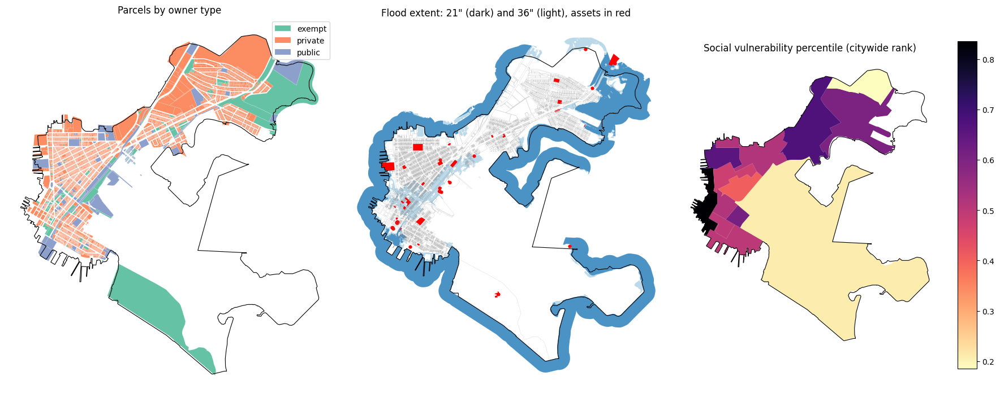

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
ax = axes[0]
parcels.plot(ax=ax, column="owner_type", legend=True, linewidth=0.1, edgecolor="white", cmap="Set2")
ax.set_title("Parcels by owner type")

ax = axes[1]
parcels.boundary.plot(ax=ax, linewidth=0.1, color="grey")
floods["36"].plot(ax=ax, color="#9ecae1", alpha=0.7)
floods["21"].plot(ax=ax, color="#3182bd", alpha=0.8)
assets.plot(ax=ax, color="red", markersize=12)
ax.set_title('Flood extent: 21" (dark) and 36" (light), assets in red')

ax = axes[2]
svi.clip(aoi).plot(ax=ax, column="vuln_pct", cmap="magma_r", legend=True)
ax.set_title("Social vulnerability percentile (citywide rank)")
for a in axes:
    aoi.boundary.plot(ax=a, color="k", linewidth=0.8); a.set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "qa_layers.png", dpi=200)

In [ ]:
!ls -la "{FIG}"

total 1171
drwx------ 2 root root    4096 Nov  6 17:27 .
drwx------ 5 root root    4096 Nov  5 20:18 ..
-rw------- 1 root root 1190823 Nov  6 17:27 qa_layers.png


## 4. Parcel feature table
One row per parcel. Columns:

| column | meaning |
|---|---|
| `flood_frac_21`, `flood_frac_36` | share of parcel area inside each flood extent |
| `ground_mean_m`, `ground_min_m` | DEM elevation over the parcel (m NAVD88) |
| `wse_21_m`, `wse_36_m` | water surface elevation used for depth (study-area constant) |
| `depth_21_m`, `depth_36_m` | mean flood depth over the flooded part of the parcel |
| `impervious_frac` | share of parcel that is impervious |
| `vuln_pct` | social vulnerability percentile of the parcel's tract |
| `critical_asset`, `asset_types` | does the parcel hold a critical asset |
| `waterfront` | parcel within 30 m of water or coastline |

**About depth.** Climate Ready Boston publishes extents, not depths. When `WSE_OVERRIDE_M` is empty, the water surface is estimated as the 95th percentile of ground elevation inside each flood extent (the flood edge is where ground meets water). Treat depth as a **proxy** for ranking, not an engineering value. If you get MC-FRM depth grids or a published water surface elevation, put it in the override.

In [ ]:
def flood_fraction(parcels, flood_gdf):
    f = flood_gdf.geometry.iloc[0]
    return (parcels.geometry.intersection(f).area / parcels.area).clip(0, 1).fillna(0)

def estimate_wse(flood_gdf, dem_path, q=95):
    with rasterio.open(dem_path) as src:
        out, _ = rio_mask(src, [mapping(flood_gdf.geometry.iloc[0])], crop=True, filled=False)
    vals = out[0].compressed()
    vals = vals[(vals > 0.5) & (vals != NODATA)]        # drop open water and harbor floor
    return float(np.percentile(vals, q))

def depth_raster(flood_gdf, wse, dem_path, out_path):
    with rasterio.open(dem_path) as src:
        dem = src.read(1, masked=True); prof = src.profile.copy()
        inside = rio_features.geometry_mask([mapping(flood_gdf.geometry.iloc[0])], out_shape=dem.shape,
                                            transform=src.transform, invert=True)
    depth = np.where(inside & ~np.ma.getmaskarray(dem), np.clip(wse - dem.filled(np.nan), 0, None), NODATA)
    prof.update(dtype="float32", nodata=NODATA, compress="lzw")
    with rasterio.open(out_path, "w", **prof) as dst:
        dst.write(depth.astype("float32"), 1)
    return out_path

def zstat(parcels, raster, stat, all_touched=False):
    # nodata must match what the rasters were written with (NODATA); np.nan here let -1 / -9999 into the means
    zs = zonal_stats(parcels.geometry, str(raster), stats=[stat], all_touched=all_touched, nodata=NODATA)
    return pd.Series([z[stat] for z in zs], index=parcels.index, dtype="float64")

def build_features(parcels, floods, dem_path, imp_path, svi, assets, water):
    feat = parcels.copy()
    wse = {}
    for s, f in floods.items():
        feat[f"flood_frac_{s}"] = flood_fraction(feat, f)
        wse[s] = WSE_OVERRIDE_M.get(s) or estimate_wse(f, dem_path)
        feat[f"wse_{s}_m"] = wse[s]
        dpath = depth_raster(f, wse[s], dem_path, PROC / f"depth_{s}.tif")
        feat[f"depth_{s}_m"] = zstat(feat, dpath, "mean").fillna(0)
        print(f'{s}": water surface {wse[s]:.2f} m NAVD88' + ("  <-- outside 1.5-4.5 m: check DEM/flood extent" if not 1.5 <= wse[s] <= 4.5 else ""))

    feat["ground_mean_m"] = zstat(feat, dem_path, "mean")
    feat["ground_min_m"] = zstat(feat, dem_path, "min")
    feat["impervious_frac"] = zstat(feat, imp_path, "mean")
    small = feat["impervious_frac"].isna()      # tiny lots on a coarse raster
    if small.any():
        feat.loc[small, "impervious_frac"] = zstat(feat[small], imp_path, "mean", all_touched=True)

    pts = feat[["parcel_id"]].copy(); pts["geometry"] = feat.representative_point()
    pts = gpd.GeoDataFrame(pts, geometry="geometry", crs=CRS)
    j = gpd.sjoin_nearest(pts, svi, how="left", max_distance=300)
    feat["vuln_pct"] = j.groupby(level=0)["vuln_pct"].first()

    a = assets.copy(); a["geometry"] = a.representative_point()
    hit = gpd.sjoin(a, feat[["geometry"]], how="inner", predicate="within")
    types = hit.groupby("index_right")["asset_type"].agg(lambda x: ", ".join(sorted(set(map(str, x)))))
    feat["asset_types"] = types.reindex(feat.index).fillna("")
    feat["critical_asset"] = feat["asset_types"] != ""

    shore = water.union_all()
    feat["dist_to_water_m"] = feat.distance(shore)
    feat["waterfront"] = feat["dist_to_water_m"] <= 30
    feat["no_resident_pop"] = feat["vuln_pct"].isna()
    feat["vuln_pct"] = feat["vuln_pct"].fillna(0)
    return feat

feat = build_features(parcels, floods, dem_path, imp_path, svi, assets, water)
feat.drop(columns="geometry").describe().T

21": water surface 2.87 m NAVD88


36": water surface 3.13 m NAVD88


,count,mean,std,min,25%,50%,75%,max
total_value,6413.0,1.272031e+06,4.026538e+06,0.000000,619600.000000,850500.000000,1.102500e+06,1.204249e+08
bldg_value,6413.0,9.284460e+05,2.863159e+06,0.000000,403800.000000,598500.000000,8.207000e+05,1.204249e+08
yr_built,5640.0,1.915877e+03,3.307770e+01,1790.000000,1900.000000,1905.000000,1.920000e+03,2.024000e+03
n_units,6413.0,1.528614e+00,3.651370e+00,1.000000,1.000000,1.000000,1.000000e+00,2.170000e+02
area_m2,6413.0,8.810362e+02,1.449419e+04,1.035285,148.998010,225.608046,3.463704e+02,9.013549e+05
flood_frac_21,6413.0,8.162279e-03,7.712955e-02,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
wse_21_m,6413.0,2.868956e+00,0.000000e+00,2.868956,2.868956,2.868956,2.868956e+00,2.868956e+00
depth_21_m,6413.0,2.039398e-02,2.236880e-01,0.000000,0.000000,0.000000,0.000000e+00,4.414384e+00
flood_frac_36,6413.0,1.267920e-01,3.088533e-01,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
wse_36_m,6413.0,3.129478e+00,0.000000e+00,3.129478,3.129478,3.129478,3.129478e+00,3.129478e+00


### EDA checks before scoring
Quick sanity checks. If any of these look off, fix the input before trusting the score.

In [ ]:
# Layer checks: fail loudly instead of silently scoring empty data.
problems = []
if feat.crs is None or feat.crs.to_string() != CRS: problems.append(f"parcel CRS is {feat.crs}")
if feat.geometry.is_empty.any() or (~feat.geometry.is_valid).any(): problems.append("empty or invalid parcel geometry")
if feat["parcel_id"].duplicated().any(): problems.append("duplicate parcel_id (condo collapse failed)")
if (feat["flood_frac_36"] > 0).sum() == 0: problems.append("no parcel touches the 36\" extent")
if (feat["flood_frac_21"] > feat["flood_frac_36"] + 0.02).any():
    problems.append("some parcels flood more at 21\" than 36\" (21\" extent should sit inside 36\")")
for c in ["ground_mean_m", "impervious_frac", "vuln_pct"]:
    share = feat[c].isna().mean()
    if share > 0.05: problems.append(f"{c} missing for {share:.0%} of parcels")
if feat["impervious_frac"].dropna().lt(0).any() or feat["impervious_frac"].dropna().gt(1).any():
    problems.append("impervious_frac outside 0-1 (nodata leaking into means)")
print("PROBLEMS:" if problems else "layer checks passed")
for p_ in problems: print("  -", p_)


layer checks passed


1064 of 6413 parcels touch the 36" extent; 109 touch 21"

flooded parcels by owner type:


,count
owner_type,
private,880
public,114
exempt,70



missing values in flooded parcels:


,0
ground_mean_m,0
impervious_frac,0
vuln_pct,11


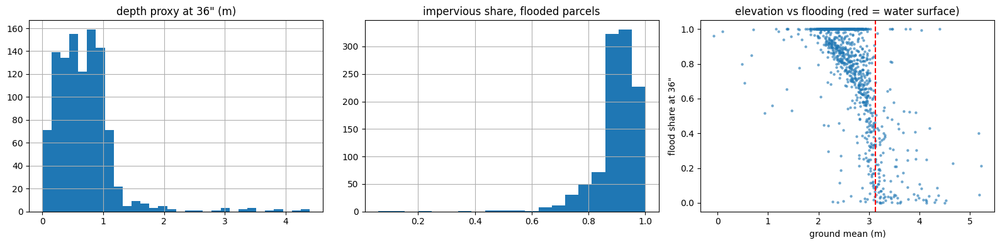

In [ ]:
flooded = feat[feat["flood_frac_36"] > 0]
print(f'{len(flooded)} of {len(feat)} parcels touch the 36" extent; {int((feat["flood_frac_21"] > 0).sum())} touch 21"')
print("\nflooded parcels by owner type:"); display(flooded["owner_type"].value_counts())
print("\nmissing values in flooded parcels:"); display(flooded[["ground_mean_m", "impervious_frac", "vuln_pct"]].isna().sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
flooded["depth_36_m"].hist(ax=axes[0], bins=30); axes[0].set_title('depth proxy at 36" (m)')
flooded["impervious_frac"].hist(ax=axes[1], bins=20); axes[1].set_title("impervious share, flooded parcels")
axes[2].scatter(flooded["ground_mean_m"], flooded["flood_frac_36"], s=5, alpha=0.5)
axes[2].axvline(feat["wse_36_m"].iloc[0], color="r", ls="--"); axes[2].set_xlabel("ground mean (m)")
axes[2].set_ylabel('flood share at 36"'); axes[2].set_title("elevation vs flooding (red = water surface)")
plt.tight_layout(); plt.savefig(FIG / "eda_checks.png", dpi=200)

## 5. Baseline scoring

- **Exposure** = `flood_frac_21 * (1 + depth_21_m) + flood_frac_36 * (1 + depth_36_m)`. Flooding sooner counts twice, deeper counts more.
- **Exposure percentile** ranked among parcels that flood at 36".
- **Risk** = `exposure_pct * ((1 - W_VULN) + W_VULN * vuln_pct)`, times `CRITICAL_ASSET_BOOST` if the parcel holds a critical asset.
- **Confidence**
  - `high`: floods at 21" (and therefore 36")
  - `medium`: floods at 36" only
  - `low`: overrides the above if ground sits within `EDGE_BAND_M` of the 36" water surface and less than a quarter of the parcel floods (small DEM errors could flip it)
- **Feasibility flags** for the solutioning step
  - `unpave_candidate`: public or exempt, impervious share at least 0.5
  - `private_hardscape`: private, impervious share at least 0.8 (needs incentives or regulation, not a city project)
  - `edge_candidate`: waterfront and floods at 36"

In [ ]:
def score(feat):
    s = feat.copy()
    s["exposure"] = (s["flood_frac_21"] * (1 + s["depth_21_m"]) + s["flood_frac_36"] * (1 + s["depth_36_m"]))
    fl = s["flood_frac_36"] > 0
    s["exposure_pct"] = 0.0
    s.loc[fl, "exposure_pct"] = s.loc[fl, "exposure"].rank(pct=True)
    v = s["vuln_pct"].fillna(s["vuln_pct"].median())
    s["risk"] = s["exposure_pct"] * ((1 - W_VULN) + W_VULN * v)
    s.loc[s["critical_asset"], "risk"] *= CRITICAL_ASSET_BOOST

    s["confidence"] = np.select([s["flood_frac_21"] > 0, fl], ["high", "medium"], default="none")
    near_edge = (s["wse_36_m"] - s["ground_mean_m"]).abs() <= EDGE_BAND_M
    s.loc[fl & near_edge & (s["flood_frac_36"] < 0.25), "confidence"] = "low"

    pub = s["owner_type"].isin(["public", "exempt"])
    s["unpave_candidate"] = pub & (s["impervious_frac"] >= 0.5)
    s["private_hardscape"] = (s["owner_type"] == "private") & (s["impervious_frac"] >= 0.8)
    s["edge_candidate"] = s["waterfront"] & fl
    s["risk_rank"] = s["risk"].rank(ascending=False, method="first").astype(int)
    return s.sort_values("risk_rank")

scored = score(feat)
cols = ["risk_rank", "parcel_id", "owner", "owner_type", "lu_desc", "risk", "confidence",
        "flood_frac_21", "flood_frac_36", "depth_36_m", "impervious_frac", "vuln_pct",
        "asset_types", "waterfront", "unpave_candidate", "private_hardscape", "edge_candidate"]
top = scored.head(TOP_N)
top[cols].round(3)

,risk_rank,parcel_id,owner,owner_type,lu_desc,risk,confidence,flood_frac_21,flood_frac_36,depth_36_m,impervious_frac,vuln_pct,asset_types,waterfront,unpave_candidate,private_hardscape,edge_candidate
3337,1,0103668000,CITY OF BOSTON,public,SCHOOL,1.131,high,0.530,0.775,1.914,0.703,0.835,school,True,True,False,True
1462,2,0101562000,MASSACHUSETTS BAY TRANSPORTATION AUTHORITY,exempt,OTHER EXEMPT BLDG,0.972,high,0.571,0.676,1.531,0.657,0.600,station,True,True,False,True
3370,3,0103711003,CITY OF BOSTON,public,POLICE STATION,0.940,high,0.445,0.448,4.282,0.838,0.519,police,True,True,False,True
3336,4,0103667050,FADILI ADEL A,private,COMMERCIAL LAND,0.918,high,0.740,0.960,3.336,0.571,0.835,,True,False,False,True
4903,5,0105382000,CITY OF BOSTON,public,FIRE STATION,0.903,high,0.659,0.766,1.106,0.870,0.498,fire_station,False,True,False,False
4983,6,0105470000,MASS TURNPIKE AUTHORITY,exempt,OTHER EXEMPT BLDG,0.869,medium,0.000,0.973,1.579,0.363,0.835,,False,False,False,False
4954,7,0105440100,122 LONDON STREET CONDOMINIUM TRUST,private,CONDO MAIN,0.855,medium,0.000,0.991,1.292,0.926,0.835,,False,False,True,False
4955,8,0105442000,HAVRE STREET APARTMENTS LLC,private,APT 4-6 UNITS,0.850,medium,0.000,1.000,1.219,0.929,0.835,,False,False,True,False
4956,9,0105443000,CORAL RAUL,private,APT 4-6 UNITS,0.844,medium,0.000,0.965,1.239,0.933,0.835,,False,False,True,False
3907,10,0104300000,RAPHAEL TRUST,private,THREE-FAM DWELLING,0.834,high,0.660,0.849,2.967,0.555,0.675,,True,False,False,True


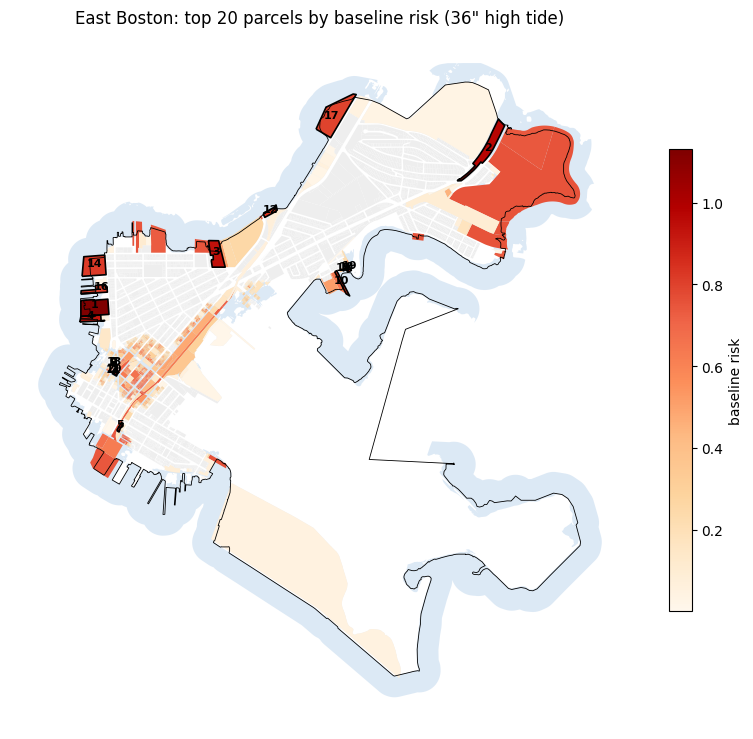

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
scored.plot(ax=ax, color="#eeeeee", linewidth=0.05, edgecolor="white")
floods["36"].plot(ax=ax, color="#c6dbef", alpha=0.6)
scored[scored["risk"] > 0].plot(ax=ax, column="risk", cmap="OrRd", linewidth=0, legend=True,
                                legend_kwds={"label": "baseline risk", "shrink": 0.6})
top.boundary.plot(ax=ax, color="k", linewidth=1.2)
for _, r in top.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(str(r["risk_rank"]), (p.x, p.y), fontsize=8, ha="center", weight="bold")
aoi.boundary.plot(ax=ax, color="k", linewidth=0.6)
ax.set_title(f'East Boston: top {TOP_N} parcels by baseline risk (36" high tide)'); ax.set_axis_off()
plt.savefig(FIG / "top_parcels.png", dpi=250, bbox_inches="tight")

In [ ]:
# Interactive check: click parcels to see every attribute
scored[scored["risk"] > 0].explore(column="risk", cmap="OrRd", tooltip=cols[:8], tiles="Esri.WorldGrayCanvas")

### Ranking stability
How much does the top list move when the weights change? Low overlap means the list depends on weights you chose, not on the data.

In [ ]:
# Ranking stability: rerun the score under different weights and compare top-N overlap.
from itertools import product
base_top = set(scored.head(TOP_N)["parcel_id"])
rows = []
for wv, boost in product([0.25, 0.5, 0.75], [1.0, 1.25, 1.5]):
    W_VULN_SAVE, BOOST_SAVE = W_VULN, CRITICAL_ASSET_BOOST
    W_VULN, CRITICAL_ASSET_BOOST = wv, boost
    alt = score(feat)
    W_VULN, CRITICAL_ASSET_BOOST = W_VULN_SAVE, BOOST_SAVE
    rho = scored.set_index("parcel_id")["risk_rank"].corr(alt.set_index("parcel_id")["risk_rank"], method="spearman")
    rows.append(dict(W_VULN=wv, boost=boost, top_overlap=len(base_top & set(alt.head(TOP_N)["parcel_id"])), spearman=round(rho, 3)))
sens_df = pd.DataFrame(rows); display(sens_df)


,W_VULN,boost,top_overlap,spearman
0,0.25,1.00,13,1.0
1,0.25,1.25,14,1.0
2,0.25,1.50,14,1.0
3,0.50,1.00,18,1.0
4,0.50,1.25,20,1.0
5,0.50,1.50,19,1.0
6,0.75,1.00,18,1.0
7,0.75,1.25,19,1.0
8,0.75,1.50,19,1.0


## 6. Export
The parcel table is the hand-off to the solutioning stage. `top_parcels.json` is already in the shape the LLM prompt will take: one object per parcel with only the fields it needs.

In [ ]:
scored.to_parquet(PROC / "east_boston_parcels_scored.parquet")
scored.drop(columns="geometry").to_csv(PROC / "east_boston_parcels_scored.csv", index=False)
top.to_crs(4326).to_file(PROC / "top_parcels.geojson", driver="GeoJSON")

llm_fields = ["parcel_id", "owner_type", "lu_desc", "risk_rank", "confidence", "flood_frac_21", "flood_frac_36",
              "depth_21_m", "depth_36_m", "ground_mean_m", "impervious_frac", "vuln_pct", "asset_types",
              "waterfront", "unpave_candidate", "private_hardscape", "edge_candidate", "area_m2"]
payload = json.loads(top[llm_fields].round(3).to_json(orient="records"))
(PROC / "top_parcels.json").write_text(json.dumps({"sources": SOURCES, "parcels": payload}, indent=2))

print("Sources used:")
for k, v in SOURCES.items():
    print(f"  {k:12s} {v}")

Sources used:
  boundary     Analyze Boston: Boston Neighborhood Boundaries
  parcels      https://gis.boston.gov/arcgis/rest/services/Assessing/Property_Assessment_FY25/MapServer
  flood_21     Analyze Boston: 21inch Sea Level Rise High Tide
  flood_36     Analyze Boston: 36inch Sea Level Rise High Tide
  dem          /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA/data/processed/dem_1m_26986.tif
  impervious   /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA/data/processed/impervious_frac_26986.tif
  social_vuln  Analyze Boston: Climate Ready Boston Social Vulnerability
  assets       OpenStreetMap via osmnx
  shoreline    OpenStreetMap via osmnx


In [ ]:
checks = {
    "impervious outside 0 to 1": ((feat.impervious_frac < 0) | (feat.impervious_frac > 1)).sum(),
    "ground elevation below -2 m or above 60 m": ((feat.ground_mean_m < -2) | (feat.ground_mean_m > 60)).sum(),
    "missing ground elevation": feat.ground_mean_m.isna().sum(),
    "missing vulnerability": feat.vuln_pct.isna().sum(),
    "floods more at 21in than 36in": (feat.flood_frac_21 > feat.flood_frac_36 + 0.01).sum(),
    "waterfront parcels": int(feat.waterfront.sum()),
    "parcels with a critical asset": int(feat.critical_asset.sum()),
}
pd.Series(checks)

,0
impervious outside 0 to 1,0
ground elevation below -2 m or above 60 m,0
missing ground elevation,0
missing vulnerability,0
floods more at 21in than 36in,0
waterfront parcels,140
parcels with a critical asset,31


In [ ]:
miss = feat[feat.vuln_pct.isna()]
pts = gpd.GeoDataFrame(miss[["parcel_id", "owner", "lu_desc"]], geometry=miss.representative_point(), crs=CRS)
chk = gpd.sjoin(pts, svi, how="left", predicate="within")
chk[["parcel_id", "owner", "lu_desc", "index_right", "vuln_pct"]]

,parcel_id,owner,lu_desc,index_right,vuln_pct
1269,0101358000,METROPOLITAN DIST COMMISSION,OTHER PUBLIC LAND,45.0,NaN
1270,0101359001,SARATOGA REALTY TRUST,TRAINING /PRIV EDUC,45.0,NaN
1271,0101359002,SARATOGA REALTY TRUST,RET/WHSL/SERVICE,45.0,NaN
1272,0101360000,BOULA RE HOLDINGS LLC,FAST FOOD Restaurant,45.0,NaN
1273,0101361000,TINTERTONTAM REALTY CORP,OFFICE 1-2 STORY,45.0,NaN
1274,0101361001,EBCDC 2 SHAWSHEEN LLC,REPAIR GARAGE,45.0,NaN
1309,0101393001,CITY OF BOSTON,OTHER PUBLIC LAND,NaN,NaN
1316,0101401000,METROPOLITAN DIST COMMISSION,OTHER EXEMPT BLDG,45.0,NaN
1317,0101402000,COMMONWEALTH OF MASS,OTHER EXEMPT BLDG,45.0,NaN
3345,0103685000,R T PROPERTIES INC,COMM MULTI-USE,NaN,NaN


# Web_test

In [ ]:
print("risk" in scored.columns)
print(PARCEL_COLS)

True
['no_resident_pop']


In [ ]:
"""
Build an interactive web map with layer toggles, ready for GitHub Pages.

Run it from the notebook AFTER the scoring section, so it can use the
results already in memory:

    %run -i web_map.py

Needs these variables from the notebook: aoi, scored, floods, svi, assets,
DATA, TOP_N. Writes <DATA parent>/docs/index.html.
"""
import folium
import branca.colormap as bcm
from branca.element import Template, MacroElement

OUT = DATA.parent / "docs"
OUT.mkdir(parents=True, exist_ok=True)

ESRI_GRAY = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
ESRI_IMG = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
SIMPLIFY_M = 0.5            # geometry simplification in meters; keeps the page light
OWNER_COLORS = {"public": "#2b8cbe", "exempt": "#9e9ac8", "private": "#bdbdbd"}

PARCEL_COLS = ["parcel_id", "risk_rank", "risk", "confidence", "owner_type", "lu_desc",
               "flood_frac_21", "flood_frac_36", "depth_36_m", "impervious_frac", "vuln_pct",
               "asset_types", "waterfront", "edge_candidate", "unpave_candidate", "no_resident_pop"]


def web(gdf, cols, tol=SIMPLIFY_M):
    """Trim columns, simplify, round numbers, reproject to lon/lat for the web."""
    cols = [c for c in cols if c in gdf.columns]
    g = gdf[cols + ["geometry"]].copy()
    g["geometry"] = g.geometry.simplify(tol, preserve_topology=True)
    g = g.to_crs(4326)
    for c in g.select_dtypes(include="float").columns:
        g[c] = g[c].round(3)
    for c in g.select_dtypes(include="bool").columns:
        g[c] = g[c].map({True: "yes", False: "no"})
    return g


def polygons(gdf, name, style, show, tooltip=None):
    fg = folium.FeatureGroup(name=name, show=show)
    folium.GeoJson(gdf.to_json(), style_function=style,
                   tooltip=folium.GeoJsonTooltip(tooltip) if tooltip else None).add_to(fg)
    return fg


# ---------------------------------------------------------------- base map
center = aoi.to_crs(4326).geometry.iloc[0].centroid
m = folium.Map(location=[center.y, center.x], zoom_start=14, tiles=None, control_scale=True)
folium.TileLayer(ESRI_GRAY, attr="Esri", name="Light gray basemap").add_to(m)
folium.TileLayer(ESRI_IMG, attr="Esri", name="Satellite basemap", show=False).add_to(m)

p = web(scored, PARCEL_COLS)
flooded = p[p["risk"] > 0]
top = p[p["risk_rank"] <= TOP_N]
tip = ["risk_rank", "owner_type", "lu_desc", "risk", "confidence", "flood_frac_36", "depth_36_m"]

# ---------------------------------------------------------------- hazard layers
for s, color, show in [("36", "#9ecae1", False), ("21", "#3182bd", False)]:
    f = web(floods[s], [], tol=1.0)
    polygons(f, f'Flood extent, {s}" sea level rise', show=show,
             style=lambda _, c=color: {"fillColor": c, "color": c, "weight": 0, "fillOpacity": 0.45}).add_to(m)

# ---------------------------------------------------------------- vulnerability
v = web(svi.clip(aoi), ["vuln_pct"], tol=2.0)
v_cm = bcm.linear.Purples_09.scale(0, 1)
polygons(v, "Social vulnerability (tracts)", show=False, tooltip=["vuln_pct"],
         style=lambda f: {"fillColor": v_cm(f["properties"]["vuln_pct"] or 0), "color": "white",
                          "weight": 0.5, "fillOpacity": 0.55}).add_to(m)

# ---------------------------------------------------------------- parcels
polygons(p, "Parcels by owner type", show=False, tooltip=["owner_type", "lu_desc"],
         style=lambda f: {"fillColor": OWNER_COLORS.get(f["properties"]["owner_type"], "#ccc"),
                          "color": "white", "weight": 0.3, "fillOpacity": 0.7}).add_to(m)

# Risk colors from one colormap; its legend goes on the MAP (a legend attached to a
# layer group throws a JavaScript error that stops every layer after it from drawing).
risk_cm = bcm.linear.OrRd_09.scale(float(flooded["risk"].min()), float(flooded["risk"].max()))
risk_cm.caption = "Baseline risk"
risk_fg = folium.FeatureGroup(name="Baseline risk (flooded parcels)", show=True)
folium.GeoJson(flooded.to_json(),
               style_function=lambda f: {"fillColor": risk_cm(f["properties"]["risk"]), "color": "white",
                                         "weight": 0.3, "fillOpacity": 0.8},
               tooltip=folium.GeoJsonTooltip(tip),
               popup=folium.GeoJsonPopup([c for c in PARCEL_COLS if c in flooded.columns])).add_to(risk_fg)
risk_fg.add_to(m)
risk_cm.add_to(m)

polygons(p[p["edge_candidate"] == "yes"], "Waterfront edge candidates", show=False,
         tooltip=["owner_type", "lu_desc"],
         style=lambda _: {"fill": False, "color": "#1a9850", "weight": 2.5}).add_to(m)
polygons(p[p["unpave_candidate"] == "yes"], "Public paved land (unpave candidates)", show=False,
         tooltip=["owner_type", "lu_desc", "impervious_frac"],
         style=lambda _: {"fill": False, "color": "#d95f0e", "weight": 2, "dashArray": "4 3"}).add_to(m)

# ---------------------------------------------------------------- top N with rank labels
top_fg = polygons(top, f"Top {TOP_N} parcels", show=True, tooltip=tip,
                  style=lambda _: {"fill": False, "color": "#111", "weight": 2.5})
for _, r in top.iterrows():
    pt = r.geometry.representative_point()
    folium.Marker([pt.y, pt.x], icon=folium.DivIcon(
        icon_size=(20, 20), icon_anchor=(10, 10),
        html=f'<div style="font:600 11px/18px sans-serif;background:#fff;border:1.5px solid #111;'
             f'border-radius:10px;width:18px;text-align:center">{int(r["risk_rank"])}</div>')).add_to(top_fg)
top_fg.add_to(m)

# ---------------------------------------------------------------- critical assets
a_fg = folium.FeatureGroup(name="Critical assets", show=True)
for _, r in assets.to_crs(4326).iterrows():
    pt = r.geometry.representative_point()
    label = f'{r.get("name") or ""} ({r["asset_type"]})'.strip()
    folium.CircleMarker([pt.y, pt.x], radius=4, color="#b2182b", fill=True, fill_opacity=1,
                        tooltip=label).add_to(a_fg)
a_fg.add_to(m)

# ---------------------------------------------------------------- outline, controls, legend
folium.GeoJson(aoi.to_crs(4326).to_json(), name="Study area", control=False,
               style_function=lambda _: {"fill": False, "color": "#333", "weight": 1.5, "dashArray": "6 4"}).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

legend = """
{% macro html(this, kwargs) %}
<div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:rgba(255,255,255,.92);
            padding:10px 12px;border-radius:6px;font:12px/1.5 sans-serif;box-shadow:0 1px 4px rgba(0,0,0,.3)">
  <b>East Boston sea level rise: baseline</b><br>
  <span style="background:#3182bd;opacity:.6;display:inline-block;width:12px;height:12px"></span> Floods at 21"
  &nbsp;<span style="background:#9ecae1;opacity:.6;display:inline-block;width:12px;height:12px"></span> Floods at 36"<br>
  <span style="background:#2b8cbe;display:inline-block;width:12px;height:12px"></span> Public
  &nbsp;<span style="background:#9e9ac8;display:inline-block;width:12px;height:12px"></span> Exempt
  &nbsp;<span style="background:#bdbdbd;display:inline-block;width:12px;height:12px"></span> Private<br>
  <span style="border:2px solid #1a9850;display:inline-block;width:10px;height:10px"></span> Edge candidate
  &nbsp;<span style="border:2px dashed #d95f0e;display:inline-block;width:10px;height:10px"></span> Unpave candidate<br>
  <span style="color:#b2182b">&#9679;</span> Critical asset
  &nbsp;&nbsp;Numbers = risk rank<br>
  <span style="color:#666">Depth is a proxy. Sources: Climate Ready Boston, City of Boston Assessing,<br>
  USGS 3DEP, OpenStreetMap.</span>
</div>
{% endmacro %}
"""
macro = MacroElement(); macro._template = Template(legend)
m.get_root().add_child(macro)
m.get_root().header.add_child(folium.Element("<title>East Boston SLR baseline</title>"))

out = OUT / "index.html"
m.save(out)
print(f"saved {out}  ({out.stat().st_size / 1e6:.1f} MB)")

saved /content/drive/MyDrive/MDE/SCI 6514: Geospatial/Final-project/EDA/docs/index.html  (6.3 MB)


In [ ]:
m

## Next steps
1. **Sanity check the top 20 with site knowledge.** Walk or street-view the top few. If a parcel looks wrong, trace which column drove it.
2. **Swap the impervious source** to MassGIS 2016 LCLU if the NLCD fallback ran.
3. **Validate with Boston 311** flooding requests: do reports cluster near your high-risk parcels?
4. **Add Chapter 91 jurisdiction and groundwater** as flags before the LLM step.
5. **Flood entry points:** East Boston has well documented low points along the waterfront where water gets in and spreads inland. Mapping these lets you group parcels by shared entry point for pathway-scale solutions.